# Phase 3 | Sampling, estimation and inference

**Track C, NACC teaching subset.** Our main question is how many more or fewer animals participants name correctly in 60 seconds per 0.1 mm greater left inferior parietal cortical thickness, after accounting for age, sex and education. Here we build toward that question by estimating means and comparing groups without covariate adjustment. Phase 4 will estimate the adjusted continuous association.

The cells below recalculate the numerical results and check them against the shared result files. The figures use the same functions as the LaTeX report.

In [1]:
import os
import sys
from io import BytesIO
from pathlib import Path

from IPython.display import Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "src/phase3_plan.py").is_file():
    raise RuntimeError("Run this notebook from the project root or its notebooks folder.")
os.chdir(root)
sys.path.insert(0, str(root))

from src import phase3_tables as tables
from src import phase3_mean_intervals as means
from src import phase3_sampling as sampling
from src import phase3_mri_contrast as contrast
from src import phase3_contrast_bootstrap as bootstrap
from src import phase3_group_comparison as groups
from src import phase3_review as review
from src.phase2_samples import load_phase2_samples
from src.phase1_figures import GRAYSCALE, plt


def show_table(headers, rows):
    def line(values):
        return "| " + " | ".join(map(str, values)) + " |"
    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)),
                                *(line(row) for row in rows)])))


def interval_text(interval, places=4):
    return ("<span dir='ltr'>[" + f"{interval['lower']:.{places}f}, "
            + f"{interval['upper']:.{places}f}]</span>")


def p_text(value):
    return f"{value:.5f}" if value >= 0.0001 else f"{value:.4g}"


def show_figure(draw, *args):
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.labelcolor": GRAYSCALE.ink, "axes.labelpad": 9,
                         "pdf.fonttype": 42, "figure.facecolor": "white"}):
        figure = draw(*args)
        with BytesIO() as buffer:
            figure.savefig(buffer, format="png", dpi=120)
            display(Image(data=buffer.getvalue()))
        plt.close(figure)

results = tables.load_results()

labels = {'sample_header': ['Analysis sample', 'Participants'],
 'samples': ['Usable UDS status and MRI thickness',
             'Normal cognition before the score filter',
             'Paired score and thickness, normal cognition',
             'Planned common Phase 4 sample'],
 'estimate_header': ['Population mean', 'N', 'Mean', 'Sample SD', 'SE', 'Individual 95% interval'],
 'measures': {'mean_score': 'Animal-naming score (correct responses)',
              'mean_thickness': 'Left cortical thickness (mm)'},
 'sampling_header': ['Mean', 'Analytic SE', 'Bootstrap SE', '95% percentile interval'],
 'group_header': ['MRI group', 'N', 'Mean score', 'Sample SD'],
 'mri_groups': {'at_or_above_cutoff': 'At or above the fixed cutoff',
                'below_cutoff': 'Below the fixed cutoff'},
 'metric_header': ['Quantity', 'Value'],
 'cutoff': 'Fixed thickness cutoff (mm)',
 'ties': 'Paired participants exactly at the cutoff',
 'delta': 'Higher-minus-lower mean difference',
 'se': 'Standard error',
 'statistic': 'Welch t statistic',
 'df': 'Degrees of freedom',
 'raw_p': 'Raw p-value',
 'holm_p': 'Holm-adjusted p-value',
 'interval': 'Individual 95% Welch interval',
 'boot_header': ['Method', 'SE', 'Individual 95% interval', 'Width'],
 'methods': ['Welch', 'Within-group bootstrap percentile'],
 'status_header': ['Cognitive status',
                   'N',
                   'Mean thickness (mm)',
                   'Sample SD (mm)',
                   'Individual 95% t interval'],
 'statuses': {'1': 'Normal cognition', '2': 'Impaired without MCI', '3': 'MCI', '4': 'Dementia'},
 'anova_f': 'Welch ANOVA F',
 'df_one': 'Numerator df',
 'df_two': 'Denominator df',
 'eta': 'Descriptive sample eta-squared',
 'diag_header': ['Cognitive status', 'Sample SD (mm)', 'Empirical skewness', 'IQR flags retained'],
 'family_header': ['Planned test', 'Raw p', 'Holm p', 'Decision after Holm'],
 'test_names': {'score_difference_by_mri': 'Score contrast across MRI groups',
                'thickness_by_status': 'Thickness across cognitive groups'},
 'reject': 'Reject the null',
 'retain': 'Do not reject the null',
 'review_header': ['Consistency check', 'Status'],
 'pass': 'Passed',
 'checks': {'raw_data_and_linkage': 'Raw-data rebuild and participant linkage',
            'registered_plan': 'Registered plan and sample rules',
            'mean_estimates': 'Two mean estimates and intervals',
            'whole_sample_bootstrap': 'Whole-sample participant bootstrap',
            'score_contrast': 'Independent MRI-group score contrast',
            'within_group_bootstrap': 'Within-group participant bootstrap',
            'cognitive_group_comparison': 'Cognitive-group thickness comparison',
            'completed_test_family': 'Completed two-test Holm table',
            'numerical_relationships': 'Numeric identities and retained draws',
            'figures': 'Five grayscale vector figures',
            'stable_inputs': 'Unchanged inputs throughout review'}}

## 1. One participant per observation and the registered plan

We link UDS and MRI one-to-one using `NACCID`, with one supplied record per person in each file. The Phase 1 build rejects blank or repeated IDs and conflicting usable cognitive-status codes. The files do not give visit or scan dates, or the number of source visits. The student reports random selection, but the sampling frame is undocumented.

We estimate both population means using the paired normal-cognition sample. The supplementary cognitive-group comparison includes everyone with usable status and thickness, so the four normal-cognition participants without usable scores remain eligible for it. We review IQR flags and retain all flagged measurements.

We set the plan after the Phase 1/2 descriptive review and before the Phase 3 calculations, making these analyses exploratory. Individual intervals have 95% confidence. The two planned tests form one family, with Holm adjustment at alpha 0.05.

In [2]:
plan = means.load_registered_plan()
samples, flow = load_phase2_samples()
paired = samples["paired_normal"]
show_table(labels["sample_header"], zip(labels["samples"], [
    len(samples["status_and_mri"]),
    flow["matched_normal_cognition_before_eligibility"],
    len(paired),
    flow["samples"]["model_normal"]["included"],
]))
show_table(labels["metric_header"], [
    (labels["cutoff"], f"{plan['mri_grouping']['cutoff_mm']:.3f}"),
    (labels["ties"], results["contrast"]["mri_grouping"]["participants_equal_to_cutoff"]),
])

| Analysis sample | Participants |
| --- | --- |
| Usable UDS status and MRI thickness | 1237 |
| Normal cognition before the score filter | 847 |
| Paired score and thickness, normal cognition | 843 |
| Planned common Phase 4 sample | 842 |

| Quantity | Value |
| --- | --- |
| Fixed thickness cutoff (mm) | 2.319 |
| Paired participants exactly at the cutoff | 3 |

## 2. Population means, estimators and intervals

Under the paired-normal eligibility rules, let $\mu_A$ denote the population mean animal-naming score and $\mu_T$ the population mean left thickness. We estimate both with $\bar x=\sum x_i/n$. The sample SD uses $n-1$, the estimated SE is $s/\sqrt n$, and the individual t interval is $\bar x\pm t_{1-\alpha/2,n-1}s/\sqrt n$.

The SD shows how much individuals differ; the SE describes how the mean would vary across repeated samples. We interpret score and thickness in their own units. If we repeatedly sampled under the stated assumptions and built a nominal 95% interval each time, about 95% of those intervals would cover the population parameter. A particular observed interval gives neither a posterior probability for the parameter nor the range containing 95% of individuals.

In [3]:
estimates = {}
for name in ("mean_score", "mean_thickness"):
    column = plan["estimands"][name]["column"]
    estimate = means.mean_interval([row[column] for row in paired], plan["confidence_level"])
    assert all(results["means"]["estimates"][name][key] == value for key, value in estimate.items())
    estimates[name] = estimate
show_table(labels["estimate_header"], [
    (labels["measures"][name], e["participants"], f"{e['mean']:.{4 if name=='mean_score' else 6}f}",
     f"{e['sample_sd']:.{4 if name=='mean_score' else 6}f}",
     f"{e['standard_error']:.{5 if name=='mean_score' else 6}f}",
     interval_text(e, 4 if name == "mean_score" else 6))
    for name, e in estimates.items()
])

| Population mean | N | Mean | Sample SD | SE | Individual 95% interval |
| --- | --- | --- | --- | --- | --- |
| Animal-naming score (correct responses) | 843 | 22.3215 | 5.4350 | 0.18719 | <span dir='ltr'>[21.9541, 22.6889]</span> |
| Left cortical thickness (mm) | 843 | 2.336446 | 0.121509 | 0.004185 | <span dir='ltr'>[2.328232, 2.344660]</span> |

## 3. Participant sampling distributions and the thickness percentile interval

Using seed **314159**, we draw **10,000** samples with replacement, each the size of the original paired-normal sample. We calculate both means from the same complete rows in each draw, keeping each person's UDS and MRI measurements together. The bootstrap SE is the sample SD of the replicate means, with denominator $B-1$. For the percentile intervals, we interpolate linearly at rank $(B-1)p$ for $p=0.025$ and $0.975$.

The lower tail in individual thickness measurements gives us a reason to compare the t and percentile intervals. Here the resampled means are approximately bell-shaped and their SEs are close to the analytic estimates. This agreement is an internal comparison using the same extract, conditional on its values and sampling assumptions.

| Mean | Analytic SE | Bootstrap SE | 95% percentile interval |
| --- | --- | --- | --- |
| Animal-naming score (correct responses) | 0.18719 | 0.18587 | <span dir='ltr'>[21.9561, 22.6821]</span> |
| Left cortical thickness (mm) | 0.004185 | 0.004185 | <span dir='ltr'>[2.328230, 2.344604]</span> |

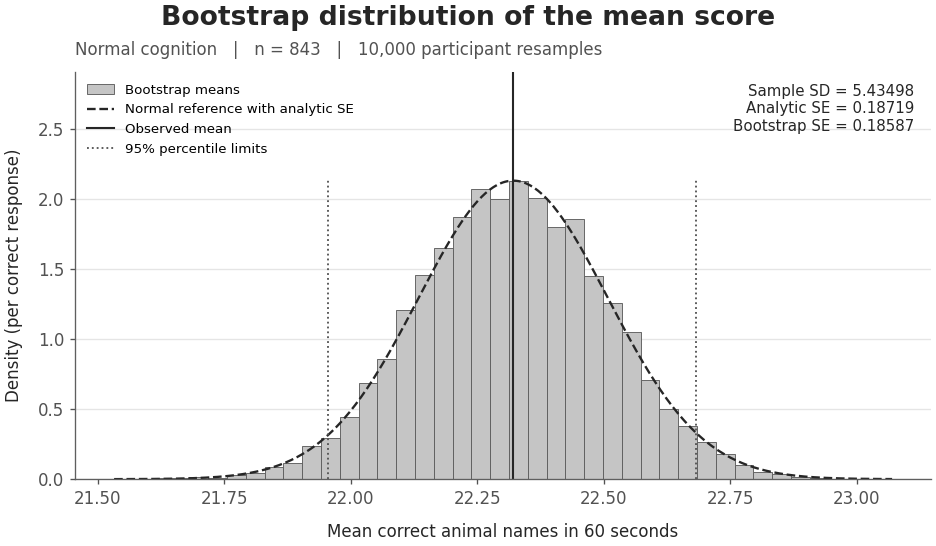

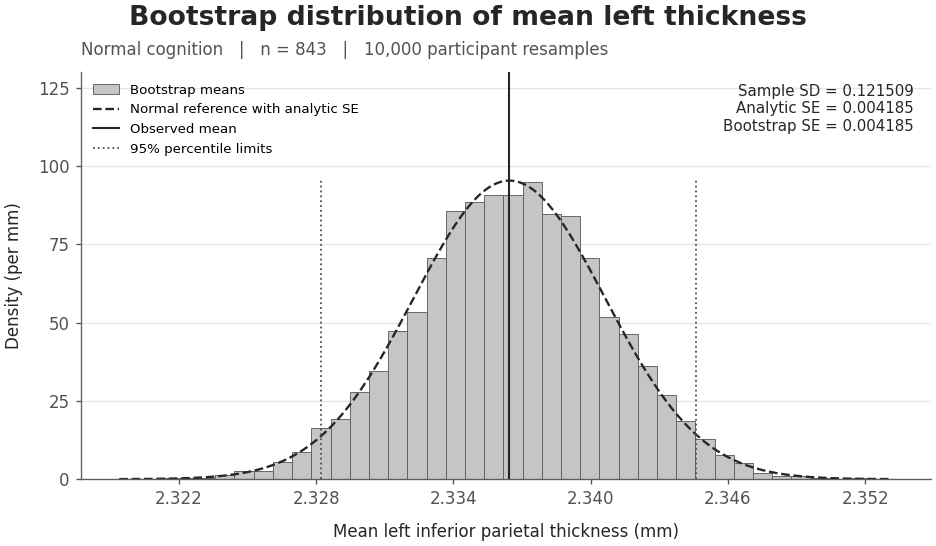

In [4]:
s = sampling.build_report()
assert s == results["sampling"]
show_table(labels["sampling_header"], [
    (labels["measures"][name], f"{e['analytic_standard_error']:.{5 if name=='mean_score' else 6}f}",
     f"{e['bootstrap_standard_error']:.{5 if name=='mean_score' else 6}f}",
     interval_text(e["percentile_interval"], 4 if name == "mean_score" else 6))
    for name, e in s["estimates"].items()
])
for name in ("mean_score", "mean_thickness"):
    show_figure(sampling.sampling_figure, name, s["estimates"][name],
                s["bootstrap_means"][name], s["bootstrap"])

## 4. Independent MRI groups and the first hypothesis test

We use the fixed Phase 2 pooled median to divide participants with normal cognition into MRI groups below and at or above the cutoff. Ties enter the higher group. The parameter is $\Delta=\mu_{A,H}-\mu_{A,L}$ in correct responses, with registered hypotheses $H_0:\Delta=0$ and $H_1:\Delta\ne0$.

Each person belongs to one group, so we use an independent-samples Welch test. Linking a person's UDS and MRI records keeps their measurements together without making the between-group comparison paired. The SE is $\sqrt{s_H^2/n_H+s_L^2/n_L}$, with Welch-Satterthwaite degrees of freedom. The method allows unequal group sizes and variances.

The interval includes zero and differences in either direction. If the population mean difference were zero and the method assumptions held, the raw p-value would give the probability of a t statistic at least as far from zero as the observed one. At the registered level, we have insufficient evidence of a mean difference. Practical equivalence has not been assessed.

In [5]:
c = contrast.build_report()
assert c == results["contrast"]
show_table(labels["group_header"], [
    (labels["mri_groups"][name], c["groups"][name]["participants"],
     f"{c['groups'][name]['score_summary']['mean']:.4f}",
     f"{c['groups'][name]['score_summary']['sample_sd']:.4f}")
    for name in contrast.GROUP_ORDER
])
e = c["estimate"]
show_table(labels["metric_header"], [
    (labels["delta"], f"{e['mean_difference']:.4f}"),
    (labels["se"], f"{e['standard_error']:.5f}"),
    (labels["statistic"], f"{e['t_statistic']:.4f}"),
    (labels["df"], f"{e['degrees_of_freedom']:.4f}"),
    (labels["raw_p"], p_text(e["p_value_raw"])),
    (labels["holm_p"], p_text(results["tests"]["tests"]["score_difference_by_mri"]["p_value_holm"])),
    (labels["interval"], interval_text(e["confidence_interval"])),
])

| MRI group | N | Mean score | Sample SD |
| --- | --- | --- | --- |
| At or above the fixed cutoff | 486 | 22.4588 | 5.5432 |
| Below the fixed cutoff | 357 | 22.1345 | 5.2861 |

| Quantity | Value |
| --- | --- |
| Higher-minus-lower mean difference | 0.3244 |
| Standard error | 0.37616 |
| Welch t statistic | 0.8624 |
| Degrees of freedom | 786.6565 |
| Raw p-value | 0.38874 |
| Holm-adjusted p-value | 0.38874 |
| Individual 95% Welch interval | <span dir='ltr'>[-0.4140, 1.0628]</span> |

## 5. Within-group participant bootstrap of the contrast

Using seed **271828**, we generate **10,000** replicates. In each replicate, we resample complete rows with replacement from the higher group first and the lower group second, keeping both observed group sizes. The 2.319 mm cutoff and the higher-minus-lower subtraction stay fixed.

We compare the 95% percentile interval with the Welch interval. Both include zero and give similar estimates of uncertainty. Each point on the interval figure marks the same observed contrast. The bootstrap distribution is centered near that contrast and describes its uncertainty; it is not a null distribution for calculating a new p-value.

| Method | SE | Individual 95% interval | Width |
| --- | --- | --- | --- |
| Welch | 0.37616 | <span dir='ltr'>[-0.4140, 1.0628]</span> | 1.4768 |
| Within-group bootstrap percentile | 0.37306 | <span dir='ltr'>[-0.4119, 1.0489]</span> | 1.4608 |

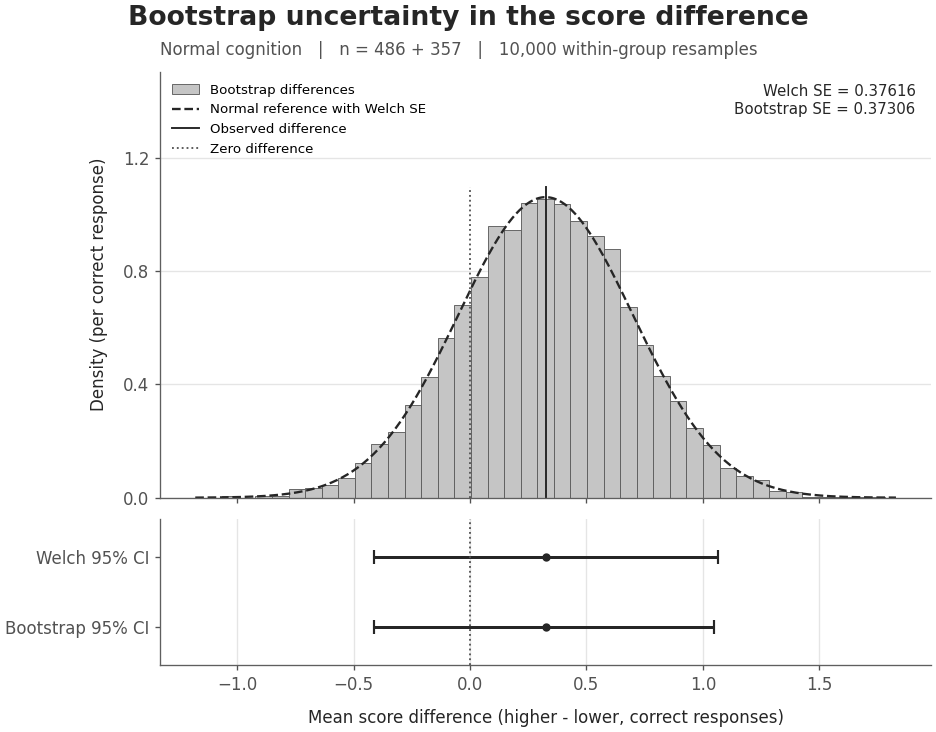

In [6]:
b = bootstrap.build_report()
assert b == results["bootstrap"]
e = b["estimate"]
show_table(labels["boot_header"], [
    (labels["methods"][0], f"{e['welch_standard_error']:.5f}",
     interval_text(e["welch_interval"]), f"{e['welch_interval']['interval_width']:.4f}"),
    (labels["methods"][1], f"{e['bootstrap_standard_error']:.5f}",
     interval_text(e["percentile_interval"]), f"{e['percentile_interval']['interval_width']:.4f}"),
])
show_figure(bootstrap.contrast_figure, b)

## 6. Thickness across cognitive groups and the second test

For this comparison, we group MRI thickness by UDS cognitive status in all eligible participants. The registered null is $H_0:\mu_1=\mu_2=\mu_3=\mu_4$; the alternative is that at least one mean differs. We use the prespecified Welch one-way ANOVA, which allows unequal variances and group sizes. Its normal-theory calibration is approximate.

If the population means were equal and the method assumptions held, the raw p-value would give the probability of an F statistic at least as large as the observed one. Group means and individual t intervals show the raw effects in millimeters. Descriptive sample eta-squared is between-group SS divided by total SS and depends on the sample composition. Under the model, the omnibus result supports a difference in at least one mean, without identifying which pair differs.

| Cognitive status | N | Mean thickness (mm) | Sample SD (mm) | Individual 95% t interval |
| --- | --- | --- | --- | --- |
| Normal cognition | 847 | 2.3364 | 0.1213 | <span dir='ltr'>[2.3282, 2.3446]</span> |
| Impaired without MCI | 7 | 2.3143 | 0.1051 | <span dir='ltr'>[2.2171, 2.4115]</span> |
| MCI | 252 | 2.2576 | 0.1728 | <span dir='ltr'>[2.2361, 2.2790]</span> |
| Dementia | 131 | 2.1541 | 0.2143 | <span dir='ltr'>[2.1170, 2.1911]</span> |

| Quantity | Value |
| --- | --- |
| Welch ANOVA F | 40.4282 |
| Numerator df | 3 |
| Denominator df | 28.7651 |
| Raw p-value | 1.914e-10 |
| Descriptive sample eta-squared | 0.1439 |

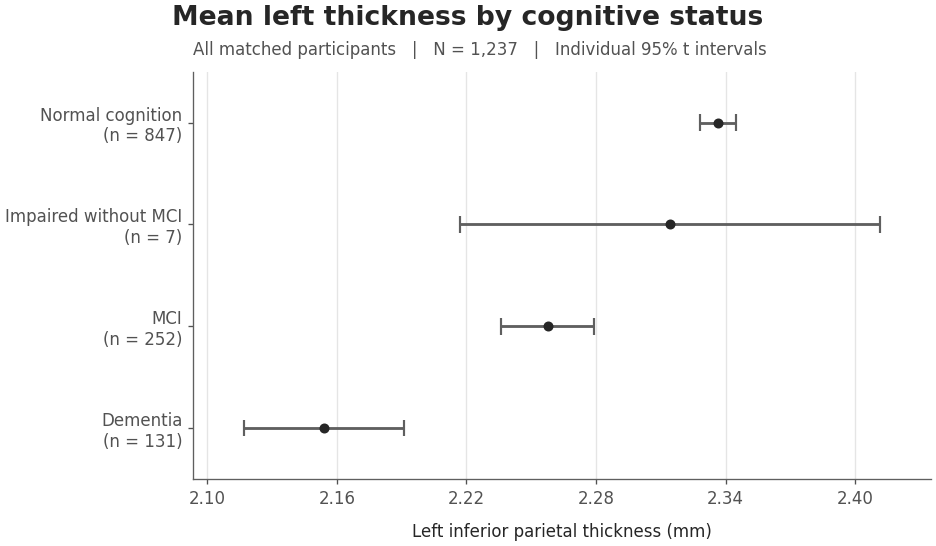

In [7]:
g = groups.build_report()
assert g == results["groups"]
show_table(labels["status_header"], [
    (labels["statuses"][str(code)], item["summary"]["usable"],
     f"{item['summary']['mean']:.4f}", f"{item['summary']['sample_sd']:.4f}",
     interval_text(item["mean_interval"]))
    for code in g["group_order"] for item in [g["groups"][str(code)]]
])
a = g["welch_anova"]
show_table(labels["metric_header"], [
    (labels["anova_f"], f"{a['f_statistic']:.4f}"),
    (labels["df_one"], a["df_numerator"]),
    (labels["df_two"], f"{a['df_denominator']:.4f}"),
    (labels["raw_p"], p_text(a["p_value_raw"])),
    (labels["eta"], f"{g['descriptive_effect']['eta_squared']:.4f}"),
])
show_figure(groups.means_figure, g)

## 7. Distribution and assumption checks

We examine group sizes, SDs, quartiles, tails, IQR flags and fitted-normal Q-Q plots alongside the test. The group classified as impaired without MCI has only seven people, including a lower-tail observation, so its mean is estimated with limited precision. We retain every flagged measurement. Welch allows unequal variances, but small groups remain sensitive to non-normal observations. We therefore interpret the result as an exploratory comparison under the stated model.

| Cognitive status | Sample SD (mm) | Empirical skewness | IQR flags retained |
| --- | --- | --- | --- |
| Normal cognition | 0.1213 | -0.950 | 15 |
| Impaired without MCI | 0.1051 | -1.373 | 1 |
| MCI | 0.1728 | -1.426 | 7 |
| Dementia | 0.2143 | -0.556 | 2 |

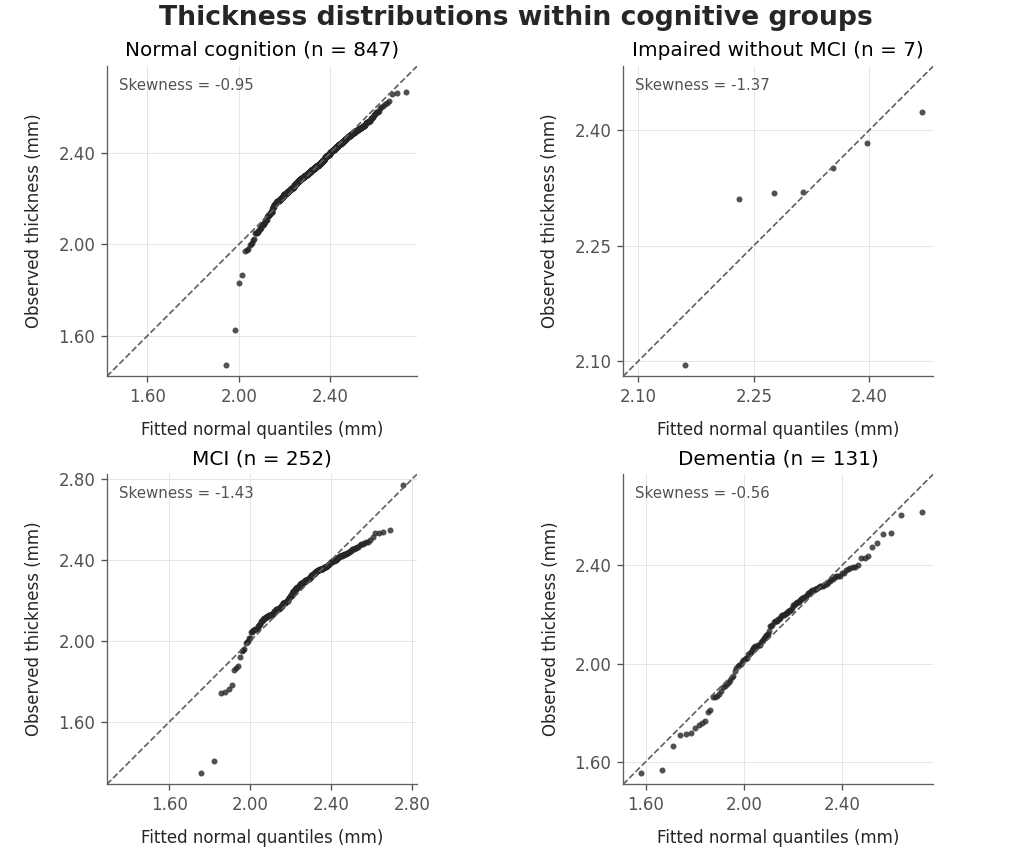

In [8]:
show_table(labels["diag_header"], [
    (labels["statuses"][str(code)], f"{item['summary']['sample_sd']:.4f}",
     f"{item['empirical_skewness']:.3f}",
     item["summary"]["iqr_review"]["below"] + item["summary"]["iqr_review"]["above"])
    for code in g["group_order"] for item in [g["groups"][str(code)]]
])
_, status_rows, _ = groups.load_status_groups()
show_figure(groups.qq_figure, g, status_rows)

## 8. Completed two-test family

Holm adjustment sorts the two raw p-values, multiplies each by the number of tests remaining, takes cumulative maxima and caps the results at one. In this family, the smaller ANOVA p-value doubles and the larger score-contrast p-value stays unchanged. The procedure allows dependence between tests, provided the raw p-values are valid. Each mean interval still has individual 95% confidence; simultaneous coverage for the family is not claimed.

In [9]:
family = groups.build_family_report(g)
assert family == results["tests"]
show_table(labels["family_header"], [
    (labels["test_names"][name], p_text(test["p_value_raw"]), p_text(test["p_value_holm"]),
     labels["reject"] if test["reject_holm"] else labels["retain"])
    for name, test in family["tests"].items()
])

| Planned test | Raw p | Holm p | Decision after Holm |
| --- | --- | --- | --- |
| Score contrast across MRI groups | 0.38874 | 0.38874 | Do not reject the null |
| Thickness across cognitive groups | 1.914e-10 | 3.828e-10 | Reject the null |

## 9. Integrated interpretation and reproducibility review

The MRI-group score contrast within normal cognition and the four-group MRI comparison address different parameters in different eligibility samples. The score contrast leaves uncertainty in both directions. The four-group comparison supports a difference in at least one mean, subject to its assumptions. Phase 4 will address the continuous adjusted question using the common eligible modeling sample.

We read effects in their original units alongside interval widths and p-values. Statistical significance alone does not establish practical importance, and a p-value is not the probability that the null is true. Source preparation and imputation details, masks identifying imputed values, clinical/MRI timing and scan-level QC are undocumented. Resampling conditions on the supplied values, so it cannot quantify extra uncertainty from their preparation. Independence across participants remains a model assumption, and the undocumented sampling frame limits generalization.

The review below rebuilds the participant data in memory, reproduces the numerical results and all five vector figures, and checks the full test family and input hashes. These checks assess computational consistency; they cannot validate the substantive assumptions.

In [10]:
current_review = review.build_review()
assert current_review == results["review"]
show_table(labels["review_header"], [
    (labels["checks"][check["check"]], labels["pass"])
    for check in current_review["checks"]
])
assert current_review["passed_checks"] == 11
assert len(review.FIGURES) == 5

| Consistency check | Status |
| --- | --- |
| Raw-data rebuild and participant linkage | Passed |
| Registered plan and sample rules | Passed |
| Two mean estimates and intervals | Passed |
| Whole-sample participant bootstrap | Passed |
| Independent MRI-group score contrast | Passed |
| Within-group participant bootstrap | Passed |
| Cognitive-group thickness comparison | Passed |
| Completed two-test Holm table | Passed |
| Numeric identities and retained draws | Passed |
| Five grayscale vector figures | Passed |
| Unchanged inputs throughout review | Passed |

## Reproduction and sources

The [README](../README.md) gives the Phase 3 analysis commands in execution order. The LaTeX report uses the same [generated numeric macros](../reports/phase3/tables.tex). The [completed test table](../reports/phase3/hypothesis_tests.json) gives the final raw and adjusted p-values, while the [review](../reports/phase3/inference_review.json) records the 11 consistency checks.

The course guide, pp. 4–5, 10–13 and 18–19, sets out the general and Track C requirements. The methods follow the official SciPy documentation for [Welch t testing](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [bootstrap intervals and SEs](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) and [Welch ANOVA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html). [R's p.adjust documentation](https://stat.ethz.ch/R-manual/R-devel/library/stats/html/p.adjust.html) explains Holm adjustment, and the [ASA principles](https://www.amstat.org/asa/files/pdfs/P-ValueStatement.pdf) guide interpretation. Raw participant files stay local.